# Childcare access in Vienna: maps

**Purpose.** This notebook produces the presentation maps of the project: smoothed travel-time surfaces, the redistribution of access under the reliability requirement, the comparison of straight-line and timetable-based proximity, and the reliable network 2SFCA (**DV2R**, the primary access measure) in relation to neighbourhood status. All maps share a common style: Vienna on a pale background, the tram/bus/U-Bahn network in black, the Danube and lakes in navy, childcare sites as small diamonds.

**Inputs.** The notebook runs in about 20 seconds and requires no routing. It reads only files already present in the repository:

| Input | Made by |
|---|---|
| `Data/socioeconomic/processed/grid250_analysis.gpkg`: 250 m cells, children, status | `socioeconomic_eda.ipynb` |
| `Data/socioeconomic/processed/grid250_access_measures.csv`: DV1, DV2R, DV2, DV3 per cell | `accessibility_analysis.ipynb` |
| `outputs/nearest_site_time_by_cell.csv`: time to the nearest site across the 60 departures | `routing.ipynb` |
| `Data/KINDERGARTENOGD.json`, `Data/BEZIRKSGRENZEOGD.json` | City of Vienna open data |
| `outputs/gtfs_route_lines_vienna.gpkg`, `outputs/gtfs_stops_vienna.csv` | cached from the Wiener Linien GTFS |
| `outputs/vienna_natural_water.geojson`, `outputs/vienna_donau_rivers.geojson` | cached from OpenStreetMap (OSMnx) |

**About the smoothed surfaces.** Maps 1–6 are *visual estimates*: cell values are binned to a fine raster and blurred with a Gaussian filter (empty bins do not count as zero), then cut into bands. They are not exact street-network isochrones. Quantities reported in the text should be taken from the cell-level results in `accessibility_analysis.ipynb`.

Figures are written to `outputs/maps/`.

In [1]:
from pathlib import Path
import warnings
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap, LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter
from shapely import contains_xy

warnings.filterwarnings("ignore", message=".*keep_geom_type.*")
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in _candidates if (p / "Data" / "KINDERGARTENOGD.json").exists())
DATA, OUT = ROOT / "Data", ROOT / "outputs"
PROC = DATA / "socioeconomic" / "processed"
FIG = OUT / "maps"; FIG.mkdir(parents=True, exist_ok=True)
CRS = "EPSG:3035"          # the grid's own equal-area CRS, metres
CAP = 30                   # routing cut-off (minutes); no route = "30+"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 200, "font.size": 12})

## 1. Load

In [2]:
grid = gpd.read_file(PROC / "grid250_analysis.gpkg")
acc = pd.read_csv(PROC / "grid250_access_measures.csv").drop(columns=["rent_eur_m2_std"])
near = pd.read_csv(OUT / "nearest_site_time_by_cell.csv").drop(columns=["nearest_p90_min", "nearest_sd_min"])   # same values are already in acc
grid = grid.merge(acc, on=["gid", "origin_id"], how="left", validate="one_to_one") \
           .merge(near, on="origin_id", how="left", validate="one_to_one")
fac = gpd.read_file(DATA / "KINDERGARTENOGD.json").to_crs(CRS)
fac["public"] = fac["TXTATT1"].eq("Öffentlich")
dist = gpd.read_file(DATA / "BEZIRKSGRENZEOGD.json").to_crs(CRS)
city = dist.union_all()
lines = gpd.read_file(OUT / "gtfs_route_lines_vienna.gpkg").to_crs(CRS)
stops = pd.read_csv(OUT / "gtfs_stops_vienna.csv")
stops = gpd.GeoDataFrame(stops, geometry=gpd.points_from_xy(stops.stop_lon, stops.stop_lat), crs=4326).to_crs(CRS)
water = gpd.read_file(OUT / "vienna_natural_water.geojson").to_crs(CRS)
donau = gpd.read_file(OUT / "vienna_donau_rivers.geojson").to_crs(CRS)

# Unreachable within the cut-off counts as the cap, so the surface reads "30+" there
for c in ["nearest_median_min", "nearest_p90_min"]:
    grid[c + "_capped"] = grid[c].fillna(CAP).clip(upper=CAP)
grid["buffer_min"] = grid["nearest_p90_min_capped"] - grid["nearest_median_min_capped"]
kids = grid[grid.children_u6 > 0].copy()
print(f"{len(grid):,} cells, {len(kids):,} with children ({kids.children_u6.sum():,.0f} children aged 0–5); "
      f"{len(fac):,} sites ({fac.public.sum()} public)")

6,950 cells, 4,298 with children (111,638 children aged 0–5); 1,682 sites (392 public)


## 2. Map style
* `base(ax)`: pale Vienna on a grey-blue background.
* `overlays(ax)`: transit lines, Danube, lakes, childcare sites, stops, city outline.
* `smooth(values)` + `bands(...)`: the smoothed raster cut into bands, for maps of the whole city (maps 1 and 3).
* `soft_bands(ax, values, ...)`: a **child-weighted** smoothed raster for the access maps (2, 4, 5, 6). Each cell counts by its number of children, so parks and industrial areas do not influence the surface. Opacity rises with the local number of children: sparsely populated fringes fade out rather than ending at a hard edge, and the extreme scores of fringe cells with very few children (a single nearby site shared by a handful of children can yield several hundred places per 100 children) carry little visual weight.

In [3]:
BG, CITY_FILL, OUTLINE = "#e8ebee", "#f6f7f4", "#263238"
TIME_LEVELS = [0, 5, 10, 15, CAP + .01]
TIME_COLOURS = ["#238b45", "#78c679", "#c2e699", "#e6e6e6"]
TIME_LABELS = ["0–5", "5–10", "10–15", "15+"]
BLUE = ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
ORANGE = ["#fdeee6", "#f9c9ad", "#f39d74", "#eb6834", "#c4501f", "#8f3a16"]
xmin, ymin, xmax, ymax = city.bounds
PAD = 600

def base(figsize=(14, 13)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_facecolor(BG)
    gpd.GeoSeries([city], crs=CRS).plot(ax=ax, color=CITY_FILL, edgecolor="none", zorder=0)
    ax.set_xlim(xmin - PAD, xmax + PAD); ax.set_ylim(ymin - PAD, ymax + PAD)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    return fig, ax

def overlays(ax, sites=True, stops_on=True, district_lines=False):
    lines.plot(ax=ax, color="black", lw=.6, alpha=.38, zorder=2)
    donau.plot(ax=ax, color="#3180AB", lw=1.1, alpha=.5, zorder=3)
    water.plot(ax=ax, color="#003153", alpha=.58, zorder=4)
    if sites:
        fac.plot(ax=ax, color="black", markersize=7, marker="D", alpha=.45, zorder=5)
    if stops_on:
        ax.scatter(stops.geometry.x, stops.geometry.y, s=4, c="grey", alpha=.45, zorder=6)
    if district_lines:
        dist.boundary.plot(ax=ax, color=OUTLINE, lw=.4, alpha=.6, zorder=7)
    gpd.GeoSeries([city], crs=CRS).boundary.plot(ax=ax, color=OUTLINE, lw=1.8, zorder=20)

BINS = 400
pts = grid.geometry.centroid
GX, GY = pts.x.to_numpy(), pts.y.to_numpy()
EDGES = (np.linspace(xmin - PAD, xmax + PAD, BINS + 1), np.linspace(ymin - PAD, ymax + PAD, BINS + 1))
XC, YC = [(e[:-1] + e[1:]) / 2 for e in EDGES]
XX, YY = np.meshgrid(XC, YC, indexing="ij")
INSIDE = contains_xy(city, XX, YY)

def smooth(values, weights=None, sigma=4, min_weight=0.02):
    """Mask-aware Gaussian smoothing of cell values onto the raster; returns (x, y) array."""
    v = np.asarray(values, float); w = np.ones_like(v) if weights is None else np.asarray(weights, float)
    ok = np.isfinite(v) & (w > 0)
    num, _, _ = np.histogram2d(GX[ok], GY[ok], bins=EDGES, weights=(v * w)[ok])
    den, _, _ = np.histogram2d(GX[ok], GY[ok], bins=EDGES, weights=w[ok])
    num, den = gaussian_filter(num, sigma), gaussian_filter(den, sigma)
    out = num / np.maximum(den, 1e-12)
    out[~INSIDE | (den < min_weight * (np.nanmax(den) if weights is not None else 1))] = np.nan
    return out

def bands(ax, Z, levels, colours, contour_at=(), alpha=.72):
    cs = ax.contourf(XX, YY, Z, levels=levels, colors=colours, alpha=alpha, zorder=1, antialiased=True)
    if contour_at:
        ax.contour(XX, YY, Z, levels=list(contour_at), colors="#52635a", linewidths=.55, alpha=.65, zorder=2)
    return cs

def soft_bands(ax, values, levels, colours, alpha_max=.85, sigma=4, fade=(.005, .05)):
    """Child-weighted banded surface. Opacity rises with the local (smoothed) number of children, from 0 at
    `fade[0]` to full at `fade[1]` (shares of the maximum), so sparsely populated fringes fade out instead of
    ending at a hard edge, and the extreme values of cells with very few children carry little visual weight."""
    v = np.asarray(values, float); w = grid["children_u6"].to_numpy(float)
    ok = np.isfinite(v) & (w > 0)
    num, _, _ = np.histogram2d(GX[ok], GY[ok], bins=EDGES, weights=(v * w)[ok])
    den, _, _ = np.histogram2d(GX[ok], GY[ok], bins=EDGES, weights=w[ok])
    num, den = gaussian_filter(num, sigma), gaussian_filter(den, sigma)
    Z = num / np.maximum(den, 1e-12)
    lo, hi = fade[0] * den.max(), fade[1] * den.max()
    A = np.clip((den - lo) / (hi - lo), 0, 1) * alpha_max
    A[~INSIDE] = 0
    rgba = ListedColormap(colours)(BoundaryNorm(levels, len(colours))(Z))
    rgba[..., 3] = A
    ax.imshow(np.transpose(rgba, (1, 0, 2)), origin="lower", interpolation="bilinear", zorder=1,
              extent=[EDGES[0][0], EDGES[0][-1], EDGES[1][0], EDGES[1][-1]])

def district_labels(ax, colour="#52514e"):
    """Thin district outlines with district numbers, for orientation."""
    dist.boundary.plot(ax=ax, color=colour, lw=.5, alpha=.55, zorder=7)
    for _, r in dist.iterrows():
        pt = r.geometry.representative_point()
        ax.text(pt.x, pt.y, str(int(r["BEZNR"])), fontsize=10, color=colour, ha="center", va="center", zorder=8,
                fontweight="bold", alpha=.8)

def note(ax, text, xy=(.015, .985), width=52, va="top"):
    """Explanatory note in a white box (axes coordinates)."""
    import textwrap
    body = "\n\n".join(textwrap.fill(par, width) for par in text.split("\n\n"))
    ax.text(*xy, body, transform=ax.transAxes, fontsize=11.5, va=va, ha="left", zorder=30, color="#0b0b0b",
            bbox=dict(boxstyle="round,pad=.6", facecolor="white", edgecolor="#c9c8c3", alpha=.95))

def colourbar(fig, ax, cmap, norm, label, ticks=None, ticklabels=None, extend="neither", shrink=.55):
    cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal",
                      shrink=shrink, pad=.01, aspect=35, ticks=ticks, extend=extend)
    if ticklabels: cb.set_ticklabels(ticklabels)
    cb.set_label(label, fontsize=13); cb.outline.set_visible(False)
    return cb

def title(ax, main, sub=None):
    ax.set_title(main + (f"\n{sub}" if sub else ""), loc="left", fontsize=16 if not sub else 15, pad=10)

def save(fig, name):
    for a in fig.axes:
        a.set_xlabel(a.get_xlabel() if a.get_label() == "<colorbar>" or a.get_xlabel().endswith("→") else "")
        a.set_ylabel(a.get_ylabel() if a.get_ylabel().endswith("→") else "")
    fig.tight_layout(pad=.5); fig.savefig(FIG / name, bbox_inches="tight", facecolor="white"); plt.show()

def wmean(s, w):
    ok = s.notna() & w.notna(); return np.average(s[ok], weights=w[ok])

time_cmap = ListedColormap(TIME_COLOURS); time_norm = BoundaryNorm(TIME_LEVELS, time_cmap.N)
TIME_TICKS = [2.5, 7.5, 12.5, (15 + CAP) / 2]

## 3. Map 1: travel time to the nearest childcare site
Median, over the 60 departures, of the walk + public transport time to the **nearest** site, in four bands; thin lines mark 5, 10 and 15 minutes. All cells are used without child weighting, so the map describes the city as a whole rather than the residential distribution of children.

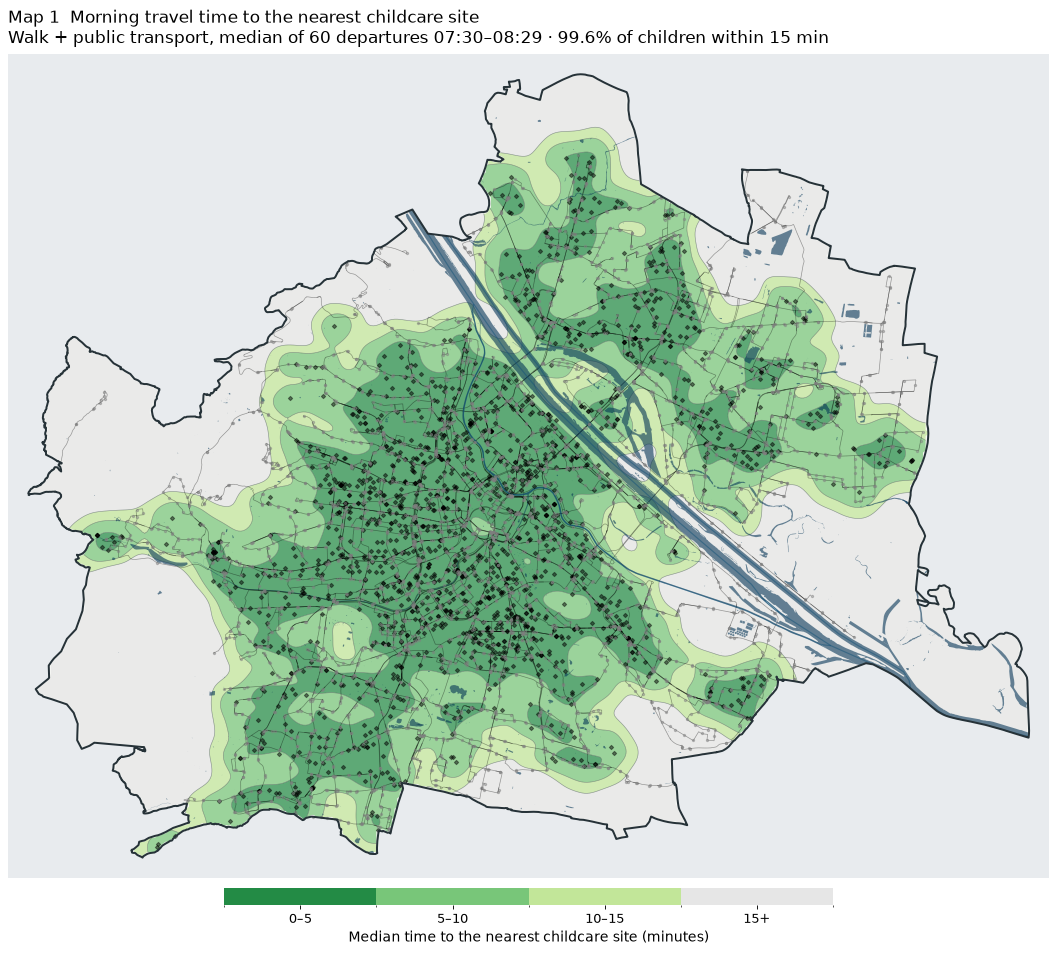

In [4]:
fig, ax = base()
bands(ax, smooth(grid["nearest_median_min_capped"]), TIME_LEVELS, TIME_COLOURS, contour_at=(5, 10, 15))
overlays(ax)
colourbar(fig, ax, time_cmap, time_norm, "Median time to the nearest childcare site (minutes)", TIME_TICKS, TIME_LABELS)
w15 = wmean(kids["nearest_median_min_capped"] <= 15, kids.children_u6)
title(ax, "Map 1  Morning travel time to the nearest childcare site",
      f"Walk + public transport, median of 60 departures 07:30–08:29 · {w15:.1%} of children within 15 min")
save(fig, "map1_nearest_site_median.png")

**Map 1b, continuous version.** The same surface without bands and with stronger smoothing (`sigma=10`). It is suited to presentation slides but is less precise.

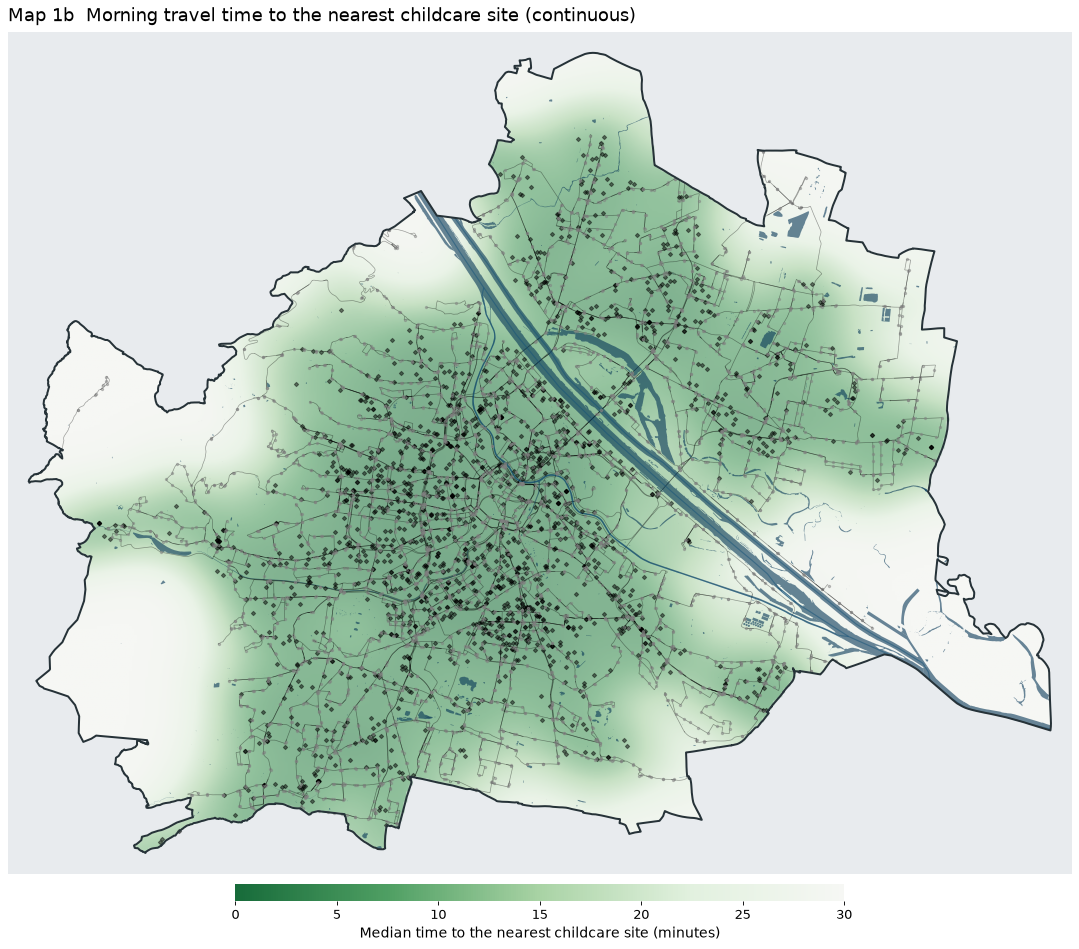

In [5]:
fig, ax = base()
Z = smooth(grid["nearest_median_min_capped"], sigma=10)
green = LinearSegmentedColormap.from_list("green", ["#176b3a", "#4f9f63", "#a9d3a5", "#e2f1df", CITY_FILL])
ax.imshow(Z.T, origin="lower", cmap=green, vmin=0, vmax=CAP, extent=[EDGES[0][0], EDGES[0][-1], EDGES[1][0], EDGES[1][-1]],
          alpha=.6, zorder=1, interpolation="bilinear")
overlays(ax)
colourbar(fig, ax, green, Normalize(0, CAP), "Median time to the nearest childcare site (minutes)", [0, 5, 10, 15, 20, 25, 30])
title(ax, "Map 1b  Morning travel time to the nearest childcare site (continuous)")
save(fig, "map1b_nearest_site_continuous.png")

## 4. Map 2: redistribution of access under the reliability requirement
**DV2R − DV2**: reliable access minus average access, in places per 100 children. Because a 2SFCA allocates all places in the city, the reliability requirement does not reduce access in aggregate but **redistributes** it. Areas shown in blue gain places: their connections are dependable, so they retain their sites while competing areas with unreliable connections drop out of the catchment. Areas shown in orange lose places, because their sites are reached by tram or bus services whose timing varies across the hour. Child-weighted smoothing. Travel time to the nearest site is almost unaffected: for 99% of children its 90th percentile equals its median, because the nearest site is usually within walking distance.

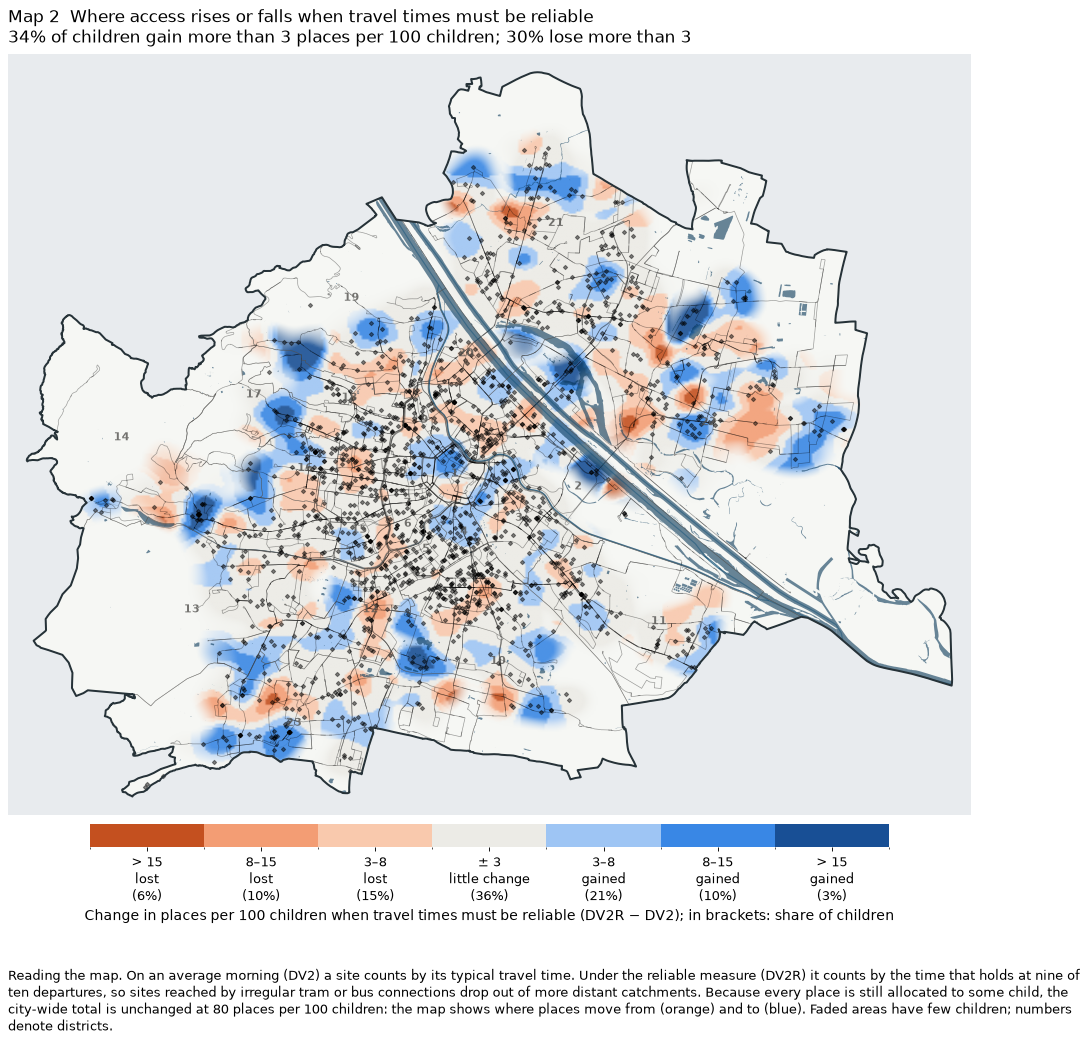

In [6]:
grid["reliability_shift"] = grid["dv2_reliable"] - grid["dv2_network"]
kids["reliability_shift"] = grid.loc[kids.index, "reliability_shift"]
S_LEVELS = [-1e6, -15, -8, -3, 3, 8, 15, 1e6]
S_COLOURS = ["#c4501f", "#f39d74", "#f9c9ad", "#ecebe6", "#9ec5f4", "#3987e5", "#184f95"]
S_LABELS = ["> 15\nlost", "8–15\nlost", "3–8\nlost", "± 3\nlittle change", "3–8\ngained", "8–15\ngained", "> 15\ngained"]
s_cmap = ListedColormap(S_COLOURS)
cls = np.digitize(kids["reliability_shift"].fillna(0), S_LEVELS[1:-1])          # class 0..6 per cell
share = np.array([kids.children_u6[cls == i].sum() for i in range(7)]) / kids.children_u6.sum()
fig, ax = base()
soft_bands(ax, grid["reliability_shift"], S_LEVELS, S_COLOURS, alpha_max=.9)
overlays(ax, stops_on=False); district_labels(ax)
colourbar(fig, ax, s_cmap, BoundaryNorm(list(range(8)), 7),
          "Change in places per 100 children when travel times must be reliable (DV2R − DV2); in brackets: share of children",
          [i + .5 for i in range(7)], [f"{l}\n({sh:.0%})" for l, sh in zip(S_LABELS, share)], shrink=.8)
ax.text(0, -.2,
        "Reading the map. On an average morning (DV2) a site counts by its typical travel time. Under the reliable measure (DV2R) "
        "it counts by the time that holds at nine of ten departures, so sites reached by irregular tram or bus connections drop out "
        "of more distant catchments. Because every place is still allocated to some child, the city-wide total is unchanged at "
        "80 places per 100 children: the map shows where places move from (orange) and to (blue). Faded areas have few children; "
        "numbers denote districts.",
        transform=ax.transAxes, va="top", ha="left", fontsize=12, wrap=True)
title(ax, "Map 2  Where access rises or falls when travel times must be reliable",
      f"{share[4:].sum():.0%} of children gain more than 3 places per 100 children; {share[:3].sum():.0%} lose more than 3")
save(fig, "map2_reliability_shift.png")

## 5. Map 3: straight-line proximity and timetable-based access
Cells shown in red lie **within 500 m of a site** in a straight line (the catchment of Pennerstorfer & Pennerstorfer), yet fewer than 90% of the 60 departures reach any site within 15 minutes, owing to rivers, railway lines, motorways or missing connections. The orange line marks the outer boundary of all 500 m buffers.

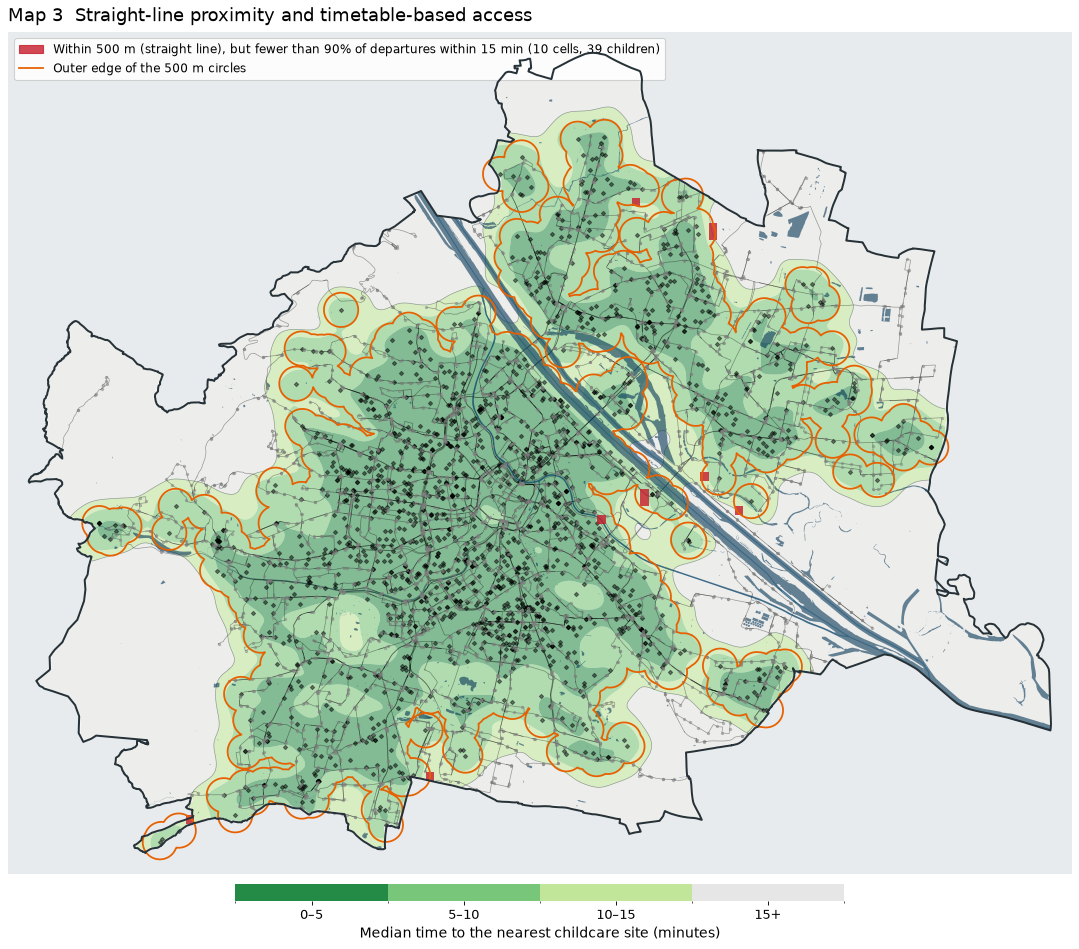

In [7]:
buf500 = fac.geometry.buffer(500).union_all()
grid["within_500m"] = gpd.GeoSeries(pts, crs=CRS).within(buf500).to_numpy()
grid["false_access"] = grid["within_500m"] & (grid["share_departures_within_15"] < .9)
fa = grid[grid.false_access & (grid.children_u6 > 0)]
fig, ax = base()
bands(ax, smooth(grid["nearest_median_min_capped"]), TIME_LEVELS, TIME_COLOURS, contour_at=(15,), alpha=.55)
fa.plot(ax=ax, color="#c51b29", edgecolor="none", alpha=.8, zorder=8)
gpd.GeoSeries(list(getattr(buf500, "geoms", [buf500])), crs=CRS).exterior.plot(ax=ax, color="#e66101", lw=1.6, zorder=9)
overlays(ax)
colourbar(fig, ax, time_cmap, time_norm, "Median time to the nearest childcare site (minutes)", TIME_TICKS, TIME_LABELS)
ax.legend(handles=[Patch(color="#c51b29", alpha=.8, label=f"Within 500 m (straight line), but fewer than 90% of departures within 15 min ({len(fa)} cells, {fa.children_u6.sum():,.0f} children)"),
                   Line2D([0], [0], color="#e66101", lw=1.6, label="Outer edge of the 500 m circles")],
          loc="upper left", fontsize=11, framealpha=.9)
title(ax, "Map 3  Straight-line proximity and timetable-based access")
save(fig, "map3_straight_line_vs_timetable.png")

## 6. Map 4: reliable network access (DV2R)
The primary access measure: the reliable network 2SFCA, with a Gaussian catchment of 15 minutes evaluated at the 90th-percentile travel time. The measure incorporates competition, since each site's places are shared among all children who can reach it. Child-weighted smoothing; the bands are **child-weighted deciles**, so that each colour represents approximately one tenth of children.
Sites are distinguished by provider (blue: public, municipal; black: private, predominantly non-profit) and scaled by the number of places.

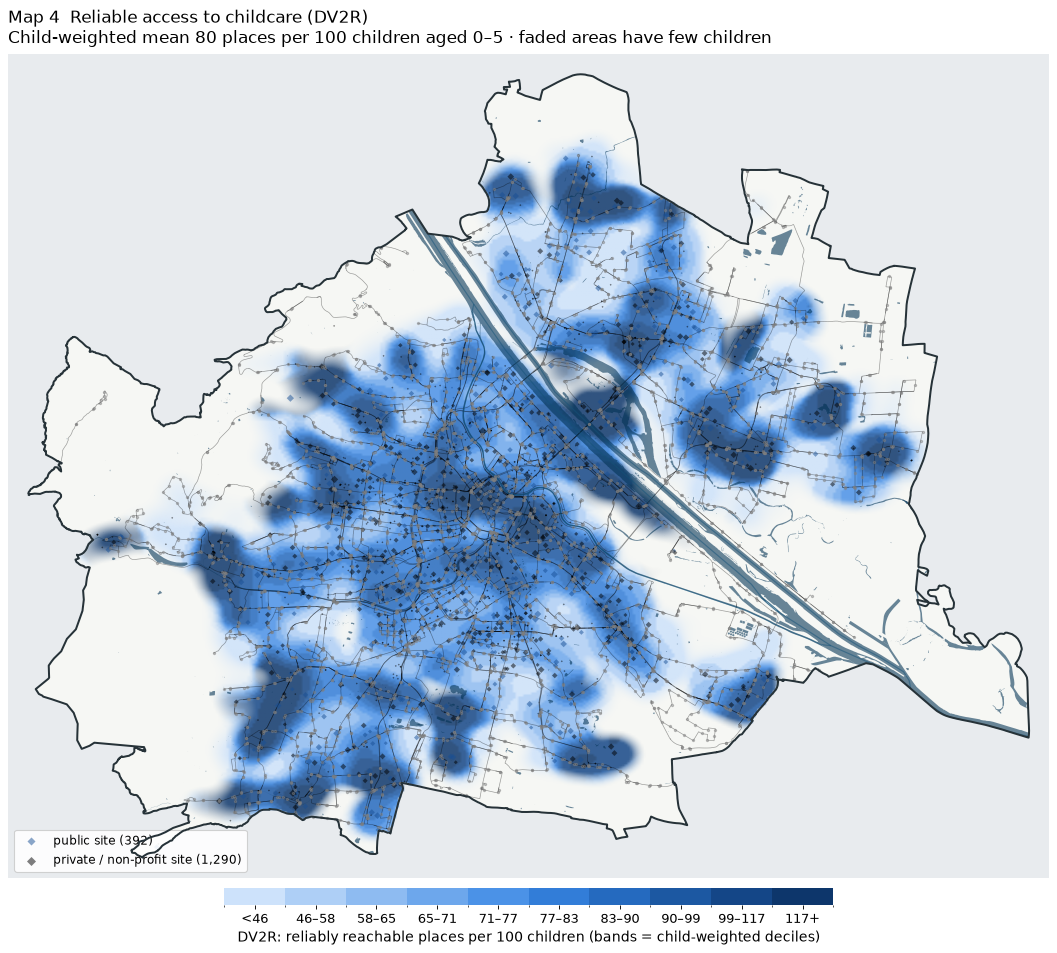

In [8]:
def site_layer(ax):
    for pub, col, lab in [(True, "#184f95", "public"), (False, "black", "private / non-profit")]:
        f = fac[fac.public == pub]
        ax.scatter(f.geometry.x, f.geometry.y, s=np.sqrt(f["KDG_3_6"].fillna(0) + f["KLEINKINDER_0_3"].fillna(0) + 1) * 1.6,
                   marker="D", c=col, alpha=.5, lw=0, zorder=5, label=f"{lab} site ({len(f):,})")

dv = kids["dv2_reliable"]
order = dv.sort_values().index
cum = kids.loc[order, "children_u6"].cumsum() / kids.children_u6.sum()
dec = [dv.loc[order][cum >= q].iloc[0] for q in np.linspace(.1, .9, 9)]
DV_LEVELS = [0] + [round(d) for d in dec] + [1e6]
DV_COLOURS = LinearSegmentedColormap.from_list("b", BLUE[1:])(np.linspace(0, 1, len(DV_LEVELS) - 1))
dv_cmap = ListedColormap(DV_COLOURS); dv_norm = BoundaryNorm(DV_LEVELS, dv_cmap.N)
fig, ax = base()
soft_bands(ax, grid["dv2_reliable"], DV_LEVELS, DV_COLOURS)
overlays(ax, sites=False); site_layer(ax)
colourbar(fig, ax, dv_cmap, BoundaryNorm(list(range(len(DV_LEVELS))), dv_cmap.N),
          "DV2R: reliably reachable places per 100 children (bands = child-weighted deciles)",
          [i + .5 for i in range(len(DV_LEVELS) - 1)],
          [f"<{DV_LEVELS[1]}"] + [f"{a}–{b}" for a, b in zip(DV_LEVELS[1:-2], DV_LEVELS[2:-1])] + [f"{DV_LEVELS[-2]}+"])
ax.legend(loc="lower left", fontsize=11, framealpha=.9, markerscale=1.5)
title(ax, "Map 4  Reliable access to childcare (DV2R)",
      f"Child-weighted mean {wmean(kids.dv2_reliable, kids.children_u6):.0f} places per 100 children aged 0–5 · faded areas have few children")
save(fig, "map4_dv2r_reliable_access.png")

## 7. Map 5: access lost at an unfavourable departure (DV3)
DV3 is the share of a cell's access that is lost at an unfavourable departure minute (the 10th-percentile departure) relative to the average departure. Child-weighted smoothing.

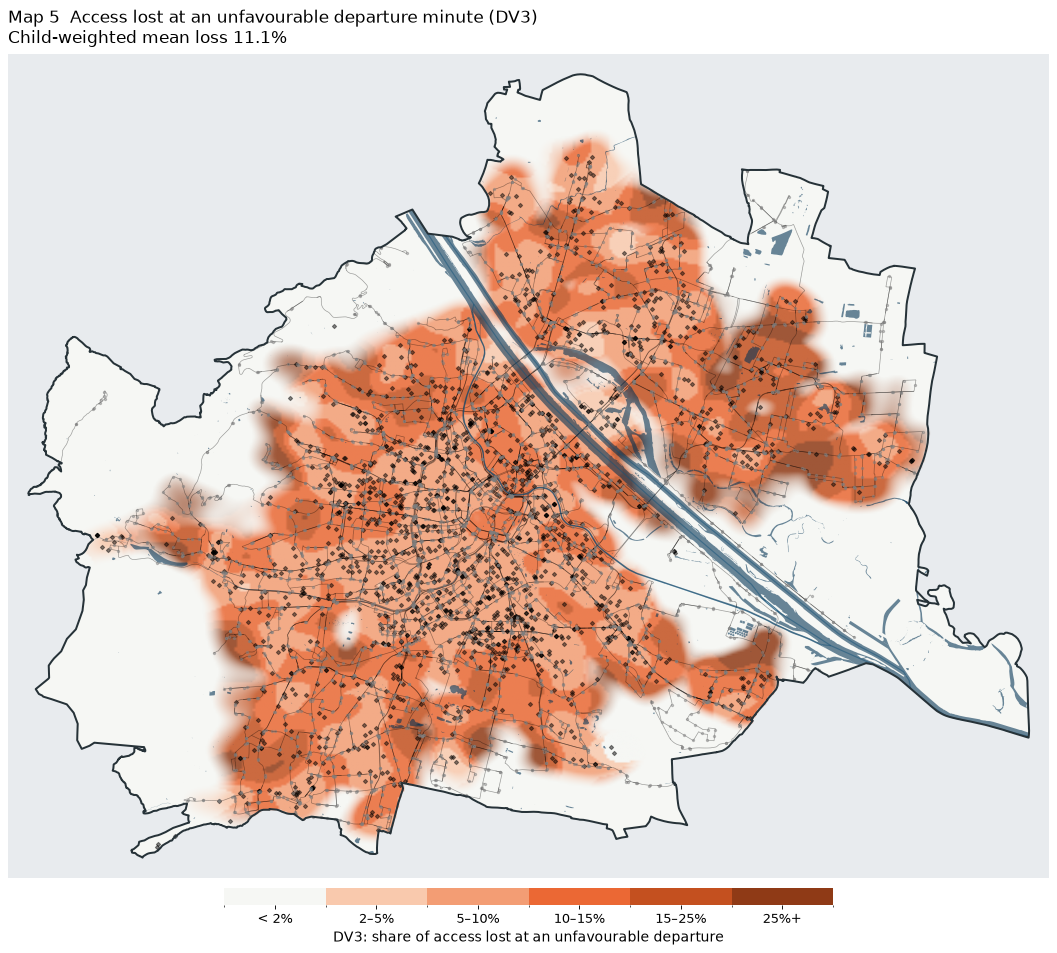

In [9]:
L_LEVELS = [-1, .02, .05, .10, .15, .25, 1]
L_COLOURS = [CITY_FILL] + ORANGE[1:]
l_cmap = ListedColormap(L_COLOURS); l_norm = BoundaryNorm(L_LEVELS, l_cmap.N)
fig, ax = base()
soft_bands(ax, grid["dv3_reliability_loss"], L_LEVELS, L_COLOURS)
overlays(ax)
colourbar(fig, ax, l_cmap, BoundaryNorm(list(range(len(L_LEVELS))), l_cmap.N), "DV3: share of access lost at an unfavourable departure",
          [i + .5 for i in range(len(L_LEVELS) - 1)], ["< 2%", "2–5%", "5–10%", "10–15%", "15–25%", "25%+"])
title(ax, "Map 5  Access lost at an unfavourable departure minute (DV3)",
      f"Child-weighted mean loss {wmean(kids.dv3_reliability_loss, kids.children_u6):.1%}")
save(fig, "map5_dv3_reliability_loss.png")

## 8. Map 6: public and private provision
DV2R split by provider. Left: public (municipal) sites only; right: private and non-profit sites. Same colour scale. In the regression analysis, access to private sites increases with neighbourhood status, whereas access to public sites is oriented towards lower-status areas; the map shows the spatial pattern underlying this result.

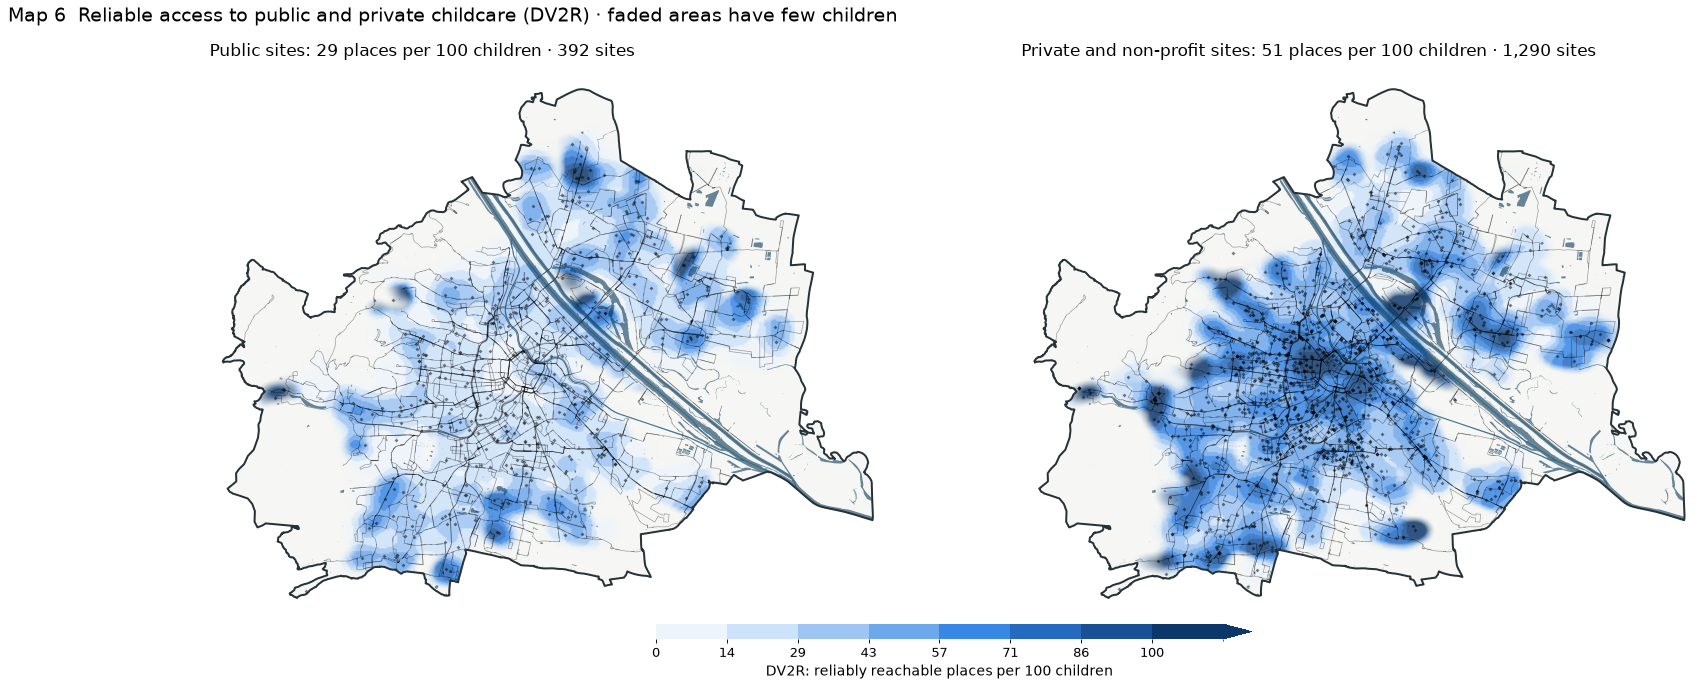

In [10]:
hi = np.nanpercentile(np.r_[kids.dv2r_public, kids.dv2r_private], 95)
P_LEVELS = list(np.linspace(0, np.ceil(hi / 10) * 10, 8).round(0)) + [1e6]
P_COLOURS = LinearSegmentedColormap.from_list("b", BLUE)(np.linspace(0, 1, len(P_LEVELS) - 1))
fig, axes = plt.subplots(1, 2, figsize=(24, 10.5))
for ax, (c, lab, pub) in zip(axes, [("dv2r_public", "Public sites", True), ("dv2r_private", "Private and non-profit sites", False)]):
    ax.set_facecolor(BG); gpd.GeoSeries([city], crs=CRS).plot(ax=ax, color=CITY_FILL, zorder=0)
    ax.set_xlim(xmin - PAD, xmax + PAD); ax.set_ylim(ymin - PAD, ymax + PAD); ax.set_axis_off()
    soft_bands(ax, grid[c], P_LEVELS, P_COLOURS)
    overlays(ax, sites=False, stops_on=False)
    f = fac[fac.public == pub]
    ax.scatter(f.geometry.x, f.geometry.y, s=6, marker="D", c="black", alpha=.5, lw=0, zorder=5)
    ax.set_title(f"{lab}: {wmean(kids[c], kids.children_u6):.0f} places per 100 children · {len(f):,} sites", loc="left", fontsize=15)
p_cmap = ListedColormap(P_COLOURS)
cb = fig.colorbar(ScalarMappable(norm=BoundaryNorm(P_LEVELS[:-1] + [P_LEVELS[-2] * 1.15], p_cmap.N), cmap=p_cmap), ax=axes,
                  orientation="horizontal", shrink=.4, pad=.02, aspect=40, extend="max")
cb.set_ticks(P_LEVELS[:-1]); cb.set_ticklabels([f"{v:.0f}" for v in P_LEVELS[:-1]])
cb.set_label("DV2R: reliably reachable places per 100 children", fontsize=13); cb.outline.set_visible(False)
fig.suptitle("Map 6  Reliable access to public and private childcare (DV2R) · faded areas have few children", x=.02, y=.96, ha="left", fontsize=17)
fig.savefig(FIG / "map6_public_vs_private.png", bbox_inches="tight", facecolor="white"); plt.show()

## 9. Map 7: access and neighbourhood status (bivariate)
Each Zählbezirk (250 statistical sub-districts) is classified jointly by two child-weighted terciles: **DV2R access** (light to blue) and **neighbourhood status** (light to pink), here measured by the rent index (€ per m² for a standard flat, the most finely resolved status measure). Dark purple denotes high status and high access, pink high status and low access, and blue low status and high access. Setting `STATUS` to `share_knowledge_JKM`, `pct_tertiary` or `net_income_eur` redraws the map with another status measure.

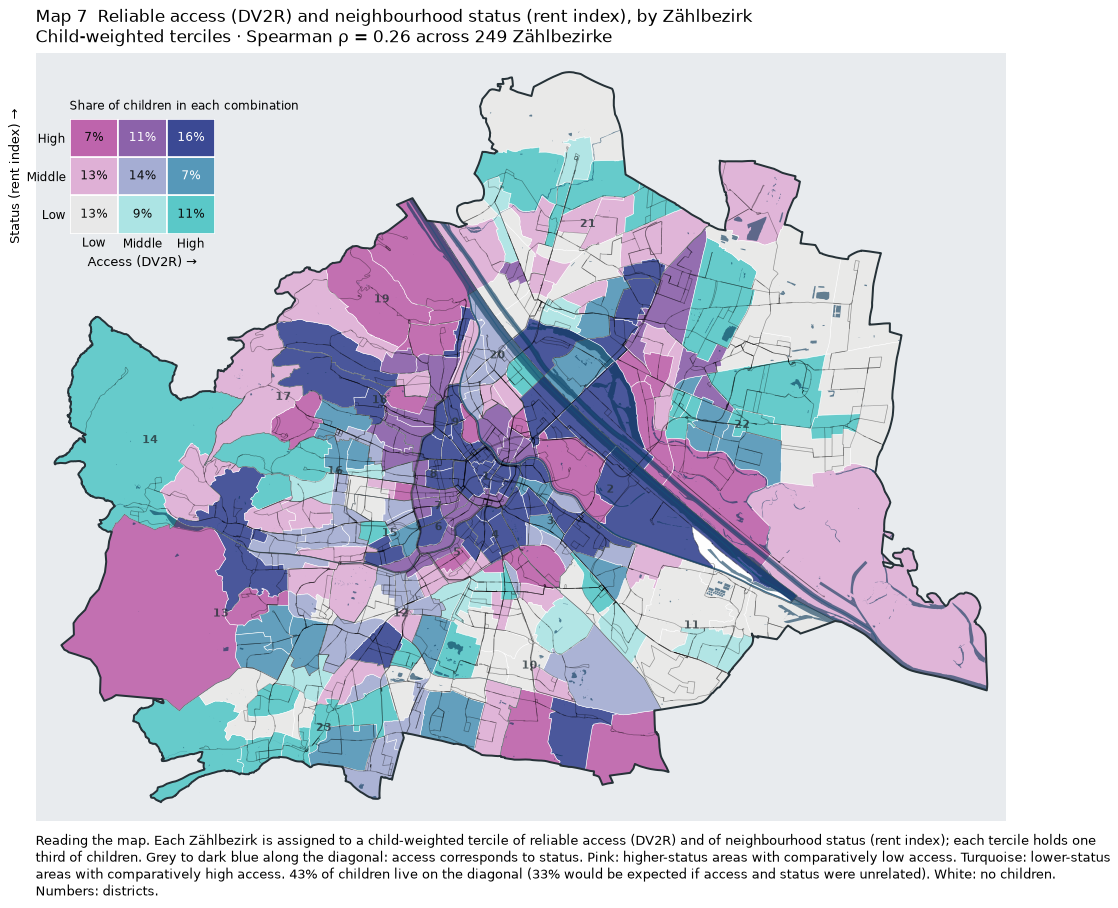

access     high      low      mid
status                           
high    17800.0   7300.0  12200.0
low     12600.0  14400.0   9700.0
mid      7400.0  15000.0  15200.0


In [11]:
STATUS, STATUS_LABEL = "rent_eur_m2_std", "rent index"
zbz = gpd.read_file(PROC / "zaehlbezirke_analysis.gpkg")[["SUB_DISTRICT_CODE", "geometry"]].to_crs(CRS)
k = kids.dropna(subset=["dv2_reliable", STATUS]).assign(w=lambda d: d.children_u6)
agg = k.groupby("SUB_DISTRICT_CODE").apply(lambda d: pd.Series({
    "dv2r": np.average(d.dv2_reliable, weights=d.w), "status": np.average(d[STATUS], weights=d.w), "children": d.w.sum()}),
    include_groups=False).reset_index()

def wterc(s, w):
    o = s.sort_values(kind="mergesort").index; c = w.loc[o].cumsum() / w.sum()
    return pd.Series(np.select([c <= 1/3, c <= 2/3], [0, 1], 2), index=o).reindex(s.index)
agg["a3"], agg["s3"] = wterc(agg.dv2r, agg.children), wterc(agg.status, agg.children)
BIV = {(0, 0): "#e8e8e8", (1, 0): "#ace4e4", (2, 0): "#5ac8c8",      # (access, status)
       (0, 1): "#dfb0d6", (1, 1): "#a5add3", (2, 1): "#5698b9",
       (0, 2): "#be64ac", (1, 2): "#8c62aa", (2, 2): "#3b4994"}
zb = zbz.merge(agg, on="SUB_DISTRICT_CODE", how="left")
zb["colour"] = [BIV.get((a, s), "#ffffff") if pd.notna(a) else "#ffffff" for a, s in zip(zb.a3, zb.s3)]

tab = agg.pivot_table(index="s3", columns="a3", values="children", aggfunc="sum").reindex(index=[0, 1, 2], columns=[0, 1, 2]).fillna(0)
tab = tab / tab.to_numpy().sum()
diag = np.trace(tab.to_numpy())
rho = agg[["dv2r", "status"]].corr("spearman").iloc[0, 1]

fig, ax = base((14, 14))
zb.plot(ax=ax, color=zb.colour, edgecolor="white", lw=.5, alpha=.92, zorder=1)
overlays(ax, sites=False, stops_on=False); district_labels(ax, colour="#263238")
lax = ax.inset_axes([.035, .765, .15, .15])                               # 3×3 key with the share of children
for (a_, s_), col in BIV.items():
    lax.add_patch(plt.Rectangle((a_, s_), 1, 1, color=col, ec="white", lw=1.5))
    lax.text(a_ + .5, s_ + .5, f"{tab.loc[s_, a_]:.0%}", ha="center", va="center", fontsize=11,
             color="white" if (a_ + s_) >= 3 else "#0b0b0b")
lax.set_xlim(0, 3); lax.set_ylim(0, 3)
lax.set_xticks([.5, 1.5, 2.5], ["Low", "Middle", "High"], fontsize=10.5)
lax.set_yticks([.5, 1.5, 2.5], ["Low", "Middle", "High"], fontsize=10.5)
lax.set_xlabel("Access (DV2R) →", fontsize=12); lax.set_ylabel(f"Status ({STATUS_LABEL}) →", fontsize=12)
lax.tick_params(length=0)
for sp in lax.spines.values(): sp.set_visible(False)
lax.set_title("Share of children in each combination", fontsize=11, loc="left", pad=8)
ax.text(.0, -.015,
        "Reading the map. Each Zählbezirk is assigned to a child-weighted tercile of reliable access (DV2R) and of "
        f"neighbourhood status ({STATUS_LABEL}); each tercile holds one third of children. Grey to dark blue along the "
        "diagonal: access corresponds to status. Pink: higher-status areas with comparatively low access. Turquoise: "
        f"lower-status areas with comparatively high access. {diag:.0%} of children live on the diagonal (33% would be "
        f"expected if access and status were unrelated). White: no children. Numbers: districts.",
        transform=ax.transAxes, va="top", ha="left", fontsize=12, wrap=True)
title(ax, f"Map 7  Reliable access (DV2R) and neighbourhood status ({STATUS_LABEL}), by Zählbezirk",
      f"Child-weighted terciles · Spearman ρ = {rho:.2f} across {len(agg)} Zählbezirke")
save(fig, f"map7_bivariate_access_{STATUS}.png")
print(pd.crosstab(agg.s3.map({0: "low", 1: "mid", 2: "high"}).rename("status"),
                  agg.a3.map({0: "low", 1: "mid", 2: "high"}).rename("access"), values=agg.children, aggfunc="sum").round(-2))

## 10. Map 8: district summary
The 23 districts, coloured by child-weighted DV2R and labelled with the district number and value. Intended as an orientation map for the report.

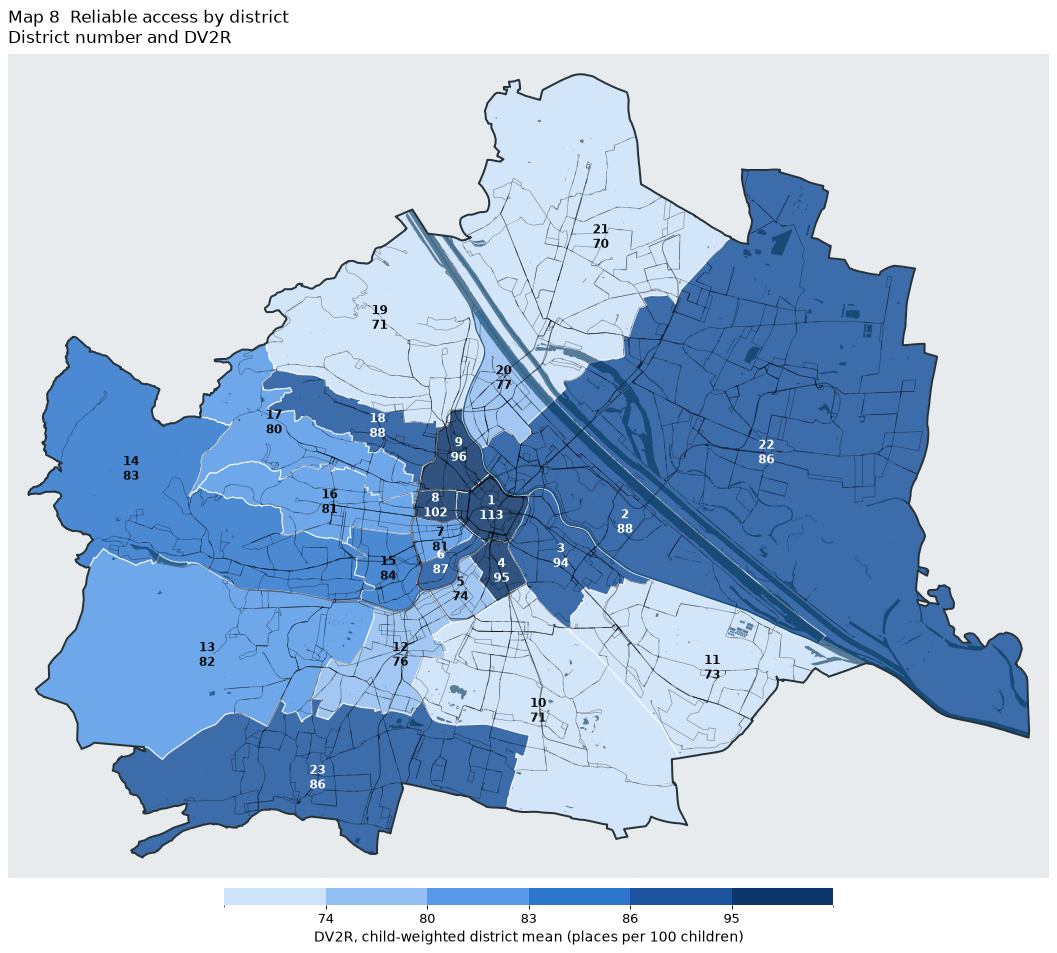

,BEZNR,NAMEK,children,dv2r,median_min
5,21,Floridsdorf,12173.6,69.6,3.7
15,19,Döbling,3578.2,70.9,4.2
13,10,Favoriten,14295.5,71.4,2.4
1,11,Simmering,6978.1,73.5,3.6
6,5,Margareten,2345.2,74.1,2.0
10,12,Meidling,5673.5,76.5,2.6
4,20,Brigittenau,4578.2,76.8,2.5
16,17,Hernals,2874.3,80.2,3.2
3,16,Ottakring,5136.7,80.9,2.4
2,7,Neubau,1420.5,81.0,1.8


In [12]:
d = kids.groupby("DISTRICT_CODE").apply(lambda g: pd.Series({
    "dv2r": np.average(g.dv2_reliable.fillna(0), weights=g.children_u6),
    "median_min": np.average(g.nearest_median_min_capped, weights=g.children_u6),
    "children": g.children_u6.sum()}), include_groups=False).reset_index()
d["BEZNR"] = (d.DISTRICT_CODE // 100 - 900).astype(int) if d.DISTRICT_CODE.max() > 100 else d.DISTRICT_CODE.astype(int)
dd = dist.assign(BEZNR=dist["BEZNR"].astype(int)).merge(d, on="BEZNR", how="left")
D_LEVELS = list(np.quantile(dd.dv2r, np.linspace(0, 1, 7)).round(0)); D_LEVELS[0] -= 1; D_LEVELS[-1] += 1
D_COLOURS = LinearSegmentedColormap.from_list("b", BLUE[1:])(np.linspace(0, 1, len(D_LEVELS) - 1))
fig, ax = base()
dd.plot(ax=ax, column="dv2r", cmap=ListedColormap(D_COLOURS), norm=BoundaryNorm(D_LEVELS, len(D_COLOURS)),
        edgecolor="white", lw=1, alpha=.85, zorder=1)
overlays(ax, sites=False, stops_on=False)
for _, r in dd.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(f"{r.BEZNR}\n{r.dv2r:.0f}", (p.x, p.y), ha="center", va="center", fontsize=11, zorder=30,
                color="white" if r.dv2r > D_LEVELS[4] else "#0b0b0b", fontweight="bold")
colourbar(fig, ax, ListedColormap(D_COLOURS), BoundaryNorm(D_LEVELS, len(D_COLOURS)),
          "DV2R, child-weighted district mean (places per 100 children)", [round(x) for x in D_LEVELS[1:-1]])
title(ax, "Map 8  Reliable access by district", "District number and DV2R")
save(fig, "map8_districts_dv2r.png")
dd[["BEZNR", "NAMEK", "children", "dv2r", "median_min"]].sort_values("BEZNR").round(1).to_csv(FIG / "district_summary.csv", index=False)
display(dd[["BEZNR", "NAMEK", "children", "dv2r", "median_min"]].sort_values("dv2r").round(1))